# 02 Exploratory data analysis of the California ComCat catalog

This notebook checks the catalog before any model is fitted: what each column means, how
complete and clean it is, how the variables are distributed, and how the quantity we forecast
behaves as a time series.

**Target.** The CSEP next-day benchmark forecasts the number of earthquakes above a magnitude
threshold in the next day, so the target here is `y_next`: tomorrow's count of M ≥ 3 events
in the region. Features are built from today and earlier only.

Fetch the data first (about a minute):

```bash
uv run quakecast fetch --full --start 1985-01-01 --min-mag 2.5
```

Helpers live in `quakecast.eda` and `quakecast.plots` and are tested in `tests/test_eda.py`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

from quakecast import catalog, eda, plots

warnings.filterwarnings("ignore", category=FutureWarning)
plots.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30, "display.precision", 3)

M0 = 3.0  # magnitude threshold for the target
df = catalog.load("../data/california_comcat_full.parquet")

## 1. Dataset overview

In [2]:
print(f"Rows (events): {len(df):,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Time span: {df['time'].min():%Y-%m-%d} to {df['time'].max():%Y-%m-%d}")
print("Column names:", list(df.columns))

Rows (events): 80,673
Number of columns: 22
Time span: 1985-01-01 to 2026-11-03
Column names: ['time', 'lat', 'lon', 'depth_km', 'mag', 'mag_type', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontal_error_km', 'depth_error_km', 'mag_error', 'mag_nst', 'status', 'location_source', 'mag_source']


Every column with its type, completeness, cardinality, an example and what it means:

In [3]:
eda.overview(df, catalog.COLUMN_DESCRIPTIONS)

,dtype,non_null,missing,missing_pct,n_unique,example,description
column,,,,,,,
time,"datetime64[us, UTC]",80673,0,0.000,80668,1985-01-01 07:08:34.580000+00:00,Origin time of the rupture (UTC)
lat,float64,80673,0,0.000,35418,32.018,Epicentre latitude (decimal degrees)
lon,float64,80673,0,0.000,37652,-116.251,Epicentre longitude (decimal degrees)
depth_km,float64,80673,0,0.000,19902,5.405,Hypocentre depth below the geoid (km); small n...
mag,float64,80673,0,0.000,357,2.84,Preferred magnitude
mag_type,str,80672,1,0.001,15,mc,"Magnitude scale: ml local, mw moment, md durat..."
nst,float64,79481,1192,1.478,261,0.0,Number of seismic stations used to locate the ...
gap,float64,79618,1055,1.308,7309,213.9,Largest azimuthal gap between stations (deg); ...
dmin,float64,59180,21493,26.642,14433,0.024,Distance from epicentre to nearest station (de...


In [4]:
df.head()

,time,lat,lon,depth_km,mag,mag_type,nst,gap,dmin,rms,net,id,updated,place,type,horizontal_error_km,depth_error_km,mag_error,mag_nst,status,location_source,mag_source
0,1985-01-01 07:08:34.580+00:00,32.018,-116.251,5.405,2.84,mc,0.0,213.9,NaN,0.268,ci,ci57747,2016-02-04 03:07:46.370+00:00,"38km ENE of Ensenada, B.C., MX",earthquake,NaN,NaN,NaN,32.0,reviewed,ci,ci
1,1985-01-01 16:45:11.360+00:00,34.628,-116.643,4.399,2.73,mc,0.0,47.6,NaN,0.314,ci,ci57759,2016-02-04 03:07:47.310+00:00,"36km NE of Lucerne Valley, CA",earthquake,NaN,NaN,NaN,73.0,reviewed,ci,ci
2,1985-01-01 19:55:26.150+00:00,37.770,-121.968,8.515,2.50,md,54.0,53.0,0.024,0.090,nc,nc36028,2016-12-02 17:00:11.580+00:00,"1 km SE of San Ramon, California",earthquake,0.15,0.250,0.1,29.0,reviewed,nc,nc
3,1985-01-02 05:24:58.220+00:00,34.046,-116.529,7.732,3.77,ml,0.0,36.2,NaN,0.213,ci,ci55737,2016-02-03 19:15:36.440+00:00,"5km E of Morongo Valley, CA",earthquake,NaN,0.499,NaN,12.0,reviewed,ci,ci
4,1985-01-02 06:37:12.740+00:00,34.047,-116.532,6.342,2.53,mc,0.0,36.2,NaN,0.162,ci,ci55678,2016-02-04 04:25:29.030+00:00,"4km E of Morongo Valley, CA",earthquake,NaN,0.842,NaN,67.0,reviewed,ci,ci


There are three kinds of column:

* **The event itself:** `time`, `lat`, `lon`, `depth_km`, `mag`, `mag_type`, `type`.
  ETAS uses only time, location and magnitude.
* **Solution quality:** `nst`, `gap`, `dmin`, `rms` and the three error columns. These
  describe how well the network constrained the event, not the earthquake.
* **Bookkeeping:** `id`, `updated`, `net`, `status` and the source columns. `updated` matters
  for reproducibility: ComCat revises events after the fact, so a refetch can change the data.

## 2. Missing values

In [5]:
missing = eda.missing_summary(df)
missing

,missing,missing_pct
mag_error,30423,37.712
horizontal_error_km,28781,35.676
dmin,21493,26.642
depth_error_km,8871,10.996
mag_nst,2065,2.560
nst,1192,1.478
gap,1055,1.308
rms,629,0.780
mag_type,1,0.001


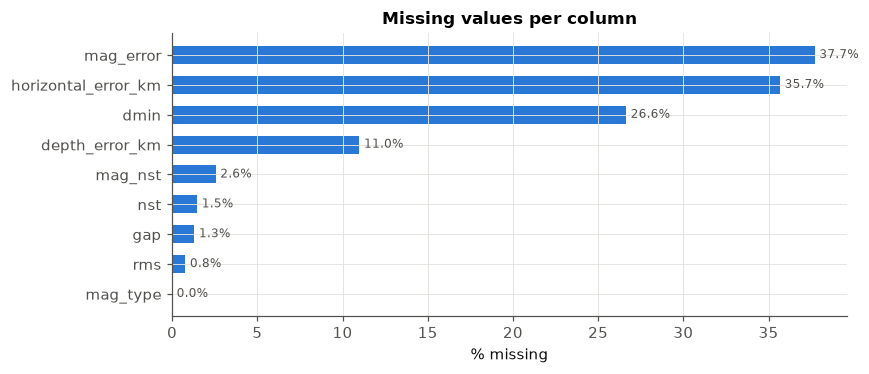

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing.index[::-1], missing["missing_pct"][::-1], color=plots.BLUE, height=0.6)
ax.set(xlabel="% missing", title="Missing values per column")
for y, v in enumerate(missing["missing_pct"][::-1]):
    ax.annotate(
        f"{v:.1f}%",
        (v, y),
        xytext=(3, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
        color=plots.INK_MUTED,
    )
plt.tight_layout()

Is missingness random, or does it depend on when the event happened?

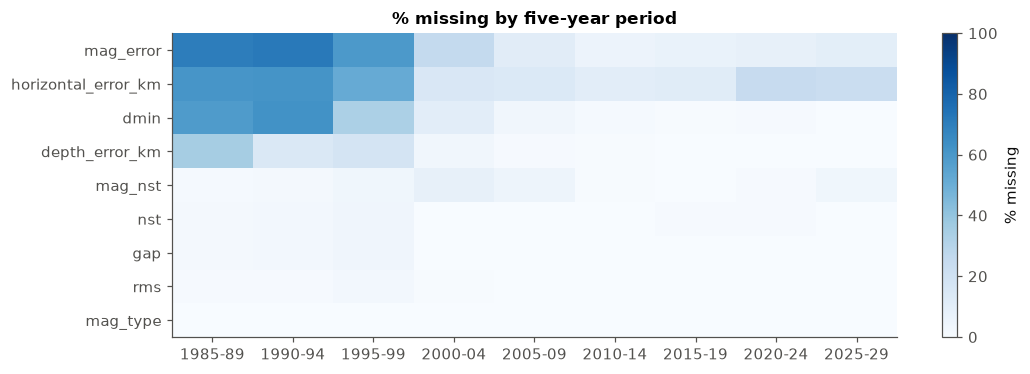

In [7]:
cols = list(missing.index)
period = (df["time"].dt.year // 5 * 5).rename("period")
by_period = df[cols].isna().groupby(period).mean().mul(100).T
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(by_period, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(by_period.shape[1]), [f"{p}-{str(p + 4)[2:]}" for p in by_period.columns])
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
ax.set_title("% missing by five-year period")
fig.colorbar(im, ax=ax, label="% missing")
plt.tight_layout()

**Missingness is structural, not random.** The location and magnitude uncertainties
(`mag_error`, `horizontal_error_km`, `dmin`) are mostly missing in the older catalog and
largely complete in recent years, because older network processing did not report them.
The core columns ETAS needs (`time`, `lat`, `lon`, `depth_km`, `mag`) have no missing values.

Implications:

* Don't impute uncertainties with a column mean, as you might in a generic tabular dataset.
  A mean error for a 1987 event is not a measurement.
* Any feature built on quality columns is really a proxy for the catalog era. If a model
  uses them, it may learn the date rather than the physics.

## 3. Categorical columns

In [8]:
for col in ["type", "mag_type", "net", "status"]:
    print(f"--- {col}")
    print(eda.value_counts_table(df[col], top=8).round(2), end="\n\n")

--- type
                    count    pct
earthquake          79363  98.38
quarry blast         1148   1.42
nuclear explosion      77   0.10
explosion              39   0.05
mining explosion       25   0.03
sonic boom             16   0.02
chemical explosion      3   0.00
rock burst              1   0.00
other                   1   0.00

--- mag_type
       count    pct
ml     39408  48.85
md     24166  29.96
mc     13036  16.16
mw      2347   2.91
mh      1156   1.43
mlr      259   0.32
mb       174   0.22
mwr       89   0.11
other     38   0.05

--- net
       count    pct
net                
ci     42888  53.16
nc     29826  36.97
nn      5993   7.43
us      1347   1.67
uw       330   0.41
uu       270   0.33
rusms     18   0.02
ew         1   0.00

--- status
           count    pct
status                 
reviewed   79719  98.82
automatic    954   1.18



* **`type`:** about 1.6% of rows are not earthquakes. They are quarry blasts, explosions and
  77 underground nuclear tests (the Nevada Test Site falls inside the bounding box). These are
  not part of the tectonic process, so they are removed below. Section 7 shows they would also
  have created a fake daily cycle.
* **`mag_type`:** the preferred magnitude mixes scales: local `ml`, duration `md`, `mc`, and
  moment `mw` for larger events. The scales are not identical, so the b-value and any
  magnitude feature mix them. The next cell shows the scale depends on event size.
* **`status`:** almost all events are reviewed. Recent automatic solutions can still change.

In [9]:
eq = catalog.earthquakes_only(df)
print(f"{len(df) - len(eq):,} non-earthquake events removed; {len(eq):,} earthquakes remain")

by_type = eq.groupby("mag_type")["mag"].agg(["count", "mean", "median", "max"])
by_type[by_type["count"] >= 100].sort_values("mean")

1,310 non-earthquake events removed; 79,363 earthquakes remain


,count,mean,median,max
mag_type,,,,
mc,12429,2.738,2.68,5.08
mh,1141,2.752,2.60,5.40
md,23664,2.780,2.72,6.00
ml,39292,2.999,2.90,6.50
mb,105,3.750,3.90,5.70
mlr,259,3.795,3.69,4.97
mw,2347,3.940,3.80,7.30


ANOVA across ['ml', 'md', 'mc', 'mw']: F = 8909.6, p = 0
Kruskal-Wallis (no normality assumption): H = 12085.2, p = 0


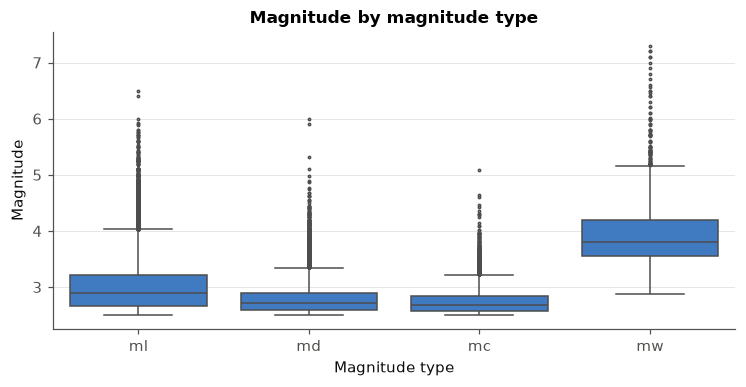

In [10]:
main = ["ml", "md", "mc", "mw"]
groups = [eq.loc[eq["mag_type"] == t, "mag"] for t in main]
f_val, p_val = stats.f_oneway(*groups)
h_val, p_kw = stats.kruskal(*groups)
print(f"ANOVA across {main}: F = {f_val:.1f}, p = {p_val:.2g}")
print(f"Kruskal-Wallis (no normality assumption): H = {h_val:.1f}, p = {p_kw:.2g}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(
    data=eq[eq["mag_type"].isin(main)],
    x="mag_type",
    y="mag",
    order=main,
    color=plots.BLUE,
    fliersize=1.5,
    linewidth=1,
    ax=ax,
)
ax.set(title="Magnitude by magnitude type", xlabel="Magnitude type", ylabel="Magnitude");

Mean magnitude differs strongly by type (p ≈ 0). That is selection, not error: networks
compute moment magnitude `mw` mainly for larger events. So `mag_type` is effectively a proxy
for magnitude and shouldn't be used as a feature.

## 4. Numeric summary: means, spread and skewness

In [11]:
num = eda.numeric_summary(eq)
num[["count", "mean", "median", "std", "min", "max", "skew", "kurtosis"]]

,count,mean,median,std,min,max,skew,kurtosis
lat,79363.0,36.027,35.861,2.772,31.500,42.992,0.256,-1.014
lon,79363.0,-118.698,-117.895,2.842,-125.400,-113.100,-0.674,-0.582
depth_km,79363.0,6.904,5.730,5.971,-3.390,77.184,1.917,7.229
mag,79363.0,2.922,2.800,0.429,2.500,7.300,2.043,6.452
nst,78283.0,30.195,22.000,32.505,0.000,369.000,1.607,4.072
gap,78399.0,116.030,81.000,84.743,0.000,360.000,0.818,-0.650
dmin,58548.0,0.183,0.084,0.233,0.000,5.654,2.844,20.827
rms,78813.0,0.179,0.156,0.387,0.000,69.320,117.270,18205.925
horizontal_error_km,51354.0,0.865,0.280,2.822,0.014,99.000,20.422,591.146
depth_error_km,71233.0,3.606,0.580,9.194,0.000,374.500,7.053,147.677


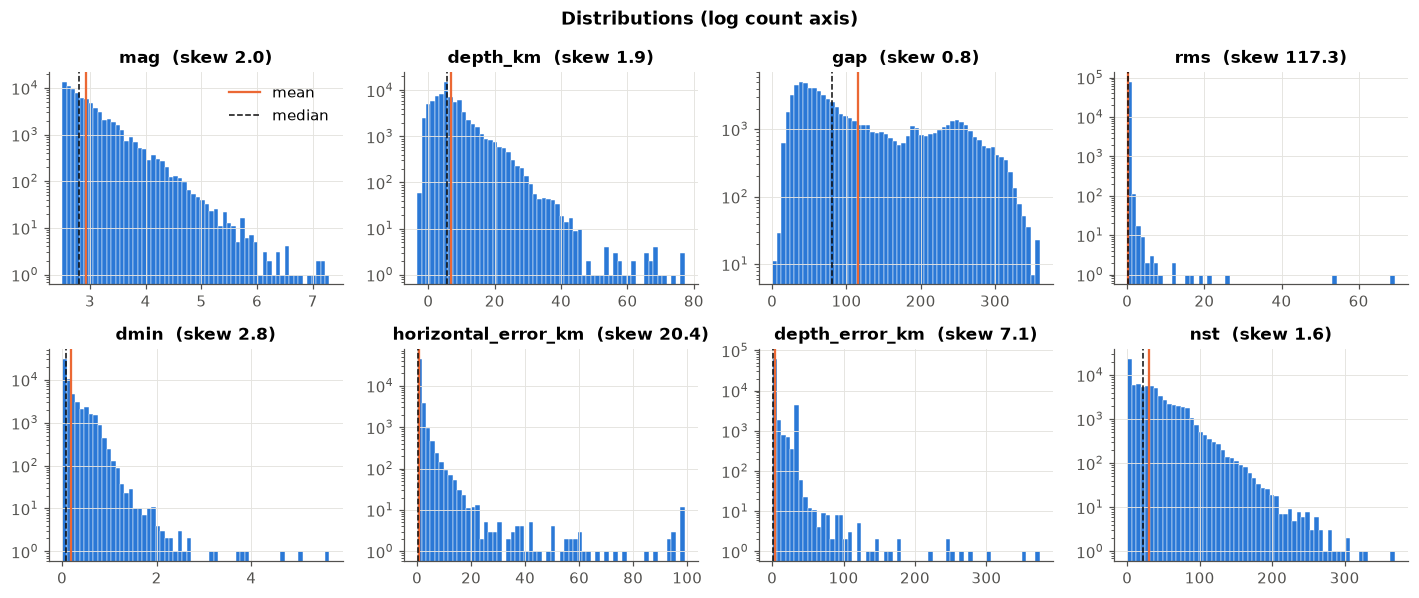

In [12]:
show = ["mag", "depth_km", "gap", "rms", "dmin", "horizontal_error_km", "depth_error_km", "nst"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, col in zip(axes.flat, show, strict=True):
    x = eq[col].dropna()
    ax.hist(x, bins=60, color=plots.BLUE, edgecolor="white", linewidth=0.3)
    ax.axvline(x.mean(), color=plots.ORANGE, lw=1.5, label="mean")
    ax.axvline(x.median(), color=plots.INK, lw=1, ls="--", label="median")
    ax.set_title(f"{col}  (skew {x.skew():.1f})")
    ax.set_yscale("log")
axes.flat[0].legend()
fig.suptitle("Distributions (log count axis)", fontweight="bold")
plt.tight_layout()

Almost every variable is **right-skewed**, with the mean above the median:

* **`mag` (skew ≈ 2):** this is the Gutenberg-Richter law, not a data problem. Magnitudes
  above completeness are exponentially distributed, so the skew is built into the physics.
  Small events dominate, and the M ≥ 6 events that matter most are rare.
* **`depth_km`:** most California seismicity is in the upper 15 km of brittle crust. The
  deep tail is mostly the Mendocino subduction zone and offshore events. Slightly negative
  depths are valid: depth is measured from the geoid, so events under mountains can be
  "above" sea level.
* **Quality columns (`rms`, error columns):** these are extremely heavy-tailed (kurtosis in
  the hundreds to thousands), dominated by a few badly located events.

For modelling, use log or rank transforms for the quality variables. Magnitude stays as it
is, because ETAS and the likelihood scores assume the exponential form.

## 5. Outliers

In [13]:
out_cols = ["mag", "depth_km", "gap", "rms", "dmin", "horizontal_error_km", "depth_error_km"]
eda.outlier_summary(eq, out_cols)

,lower_fence,upper_fence,n_outside_iqr,pct_outside_iqr,n_robust_z_gt_3.5,min,max
column,,,,,,,
mag,1.915,3.795,3921,4.941,3454,2.500,7.300
depth_km,-6.145,18.514,4232,5.332,2753,-3.390,77.184
gap,-160.600,393.000,0,0.000,1039,0.000,360.000
rms,-0.108,0.420,2416,3.065,1412,0.000,69.320
dmin,-0.253,0.519,5973,10.202,8920,0.000,5.654
horizontal_error_km,-0.695,1.585,6351,12.367,9668,0.014,99.000
depth_error_km,-1.300,3.020,11377,15.972,13239,0.000,374.500


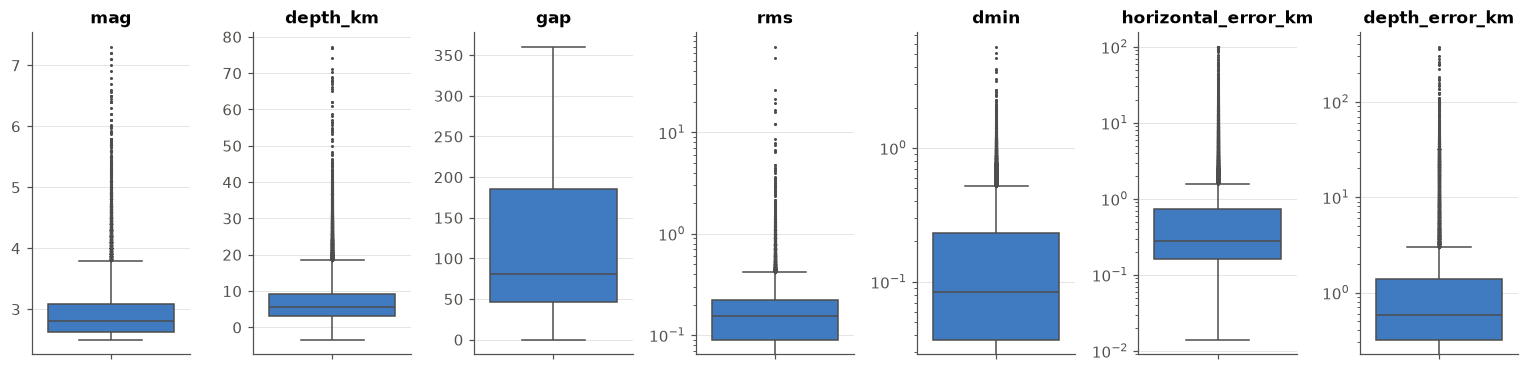

In [14]:
fig, axes = plt.subplots(1, len(out_cols), figsize=(14, 3.5))
for ax, col in zip(axes, out_cols, strict=True):
    sns.boxplot(y=eq[col].dropna(), ax=ax, color=plots.BLUE, fliersize=1, linewidth=1)
    ax.set(title=col, ylabel="")
    if col in ("rms", "dmin", "horizontal_error_km", "depth_error_km"):
        ax.set_yscale("log")
plt.tight_layout()

The most extreme rows: are they physics or bad data?

In [15]:
cols = ["time", "mag", "depth_km", "rms", "depth_error_km", "gap", "nst", "place"]
print("Largest rms residuals")
display(eq.nlargest(4, "rms")[cols])
print("Largest depth errors")
display(eq.nlargest(4, "depth_error_km")[cols])
print("Largest magnitudes")
display(eq.nlargest(6, "mag")[cols])

Largest rms residuals


,time,mag,depth_km,rms,depth_error_km,gap,nst,place
46624,2007-02-26 12:21:02.140+00:00,5.40,4.957,69.32,31.61,329.0,21.0,"52km W of Ferndale, CA"
39194,2001-08-10 20:19:55.260+00:00,3.30,4.813,53.97,31.61,334.0,7.0,"20km SW of Redway, CA"
9836,1988-12-07 22:54:18.950+00:00,2.96,2.704,26.10,78.11,268.0,6.0,"9 km SE of Milford, California"
8875,1988-06-11 19:57:25.620+00:00,2.79,4.518,21.55,73.16,156.0,4.0,"5 km SE of Comptche, California"


Largest depth errors


,time,mag,depth_km,rms,depth_error_km,gap,nst,place
59928,2014-08-23 20:16:39.933+00:00,2.50,0.400,0.015,374.500,128.97,3.0,"43 km E of Fort Bidwell, California"
35985,1999-10-23 02:22:49.200+00:00,2.56,4.783,0.122,355.209,80.90,0.0,"17km SW of Ludlow, California"
17432,1992-06-29 01:23:19.780+00:00,3.92,5.107,0.228,304.812,86.80,0.0,"33km NE of Boron, California"
24907,1994-01-18 13:31:40.140+00:00,2.70,5.660,0.281,277.538,90.70,0.0,"5km ENE of Chatsworth, California"


Largest magnitudes


,time,mag,depth_km,rms,depth_error_km,gap,nst,place
17059,1992-06-28 11:57:34.130+00:00,7.3,-0.097,0.194,0.31,43.4,0.0,"The 1992 Landers, California Earthquake"
15846,1992-04-25 18:06:05.180+00:00,7.2,9.856,0.070,0.64,115.0,9.0,"The 1992 Petrolia, California Earthquake"
50821,2010-04-04 22:40:42.360+00:00,7.2,9.987,0.110,31.61,239.0,10.0,"The 2010 Sierra El Mayor, B.C., Mexico Earthquake"
34855,1999-10-16 09:46:44.460+00:00,7.1,13.730,0.310,31.61,57.0,73.0,"The 1999 Hector Mine, California Earthquake"
65683,2019-07-06 03:19:53.040+00:00,7.1,8.000,0.220,31.61,43.0,77.0,Ridgecrest Earthquake Sequence
76322,2024-12-05 18:44:21.110+00:00,7.0,10.000,0.230,31.61,229.0,172.0,"2024 Offshore Cape Mendocino, California Earth..."


**Don't drop rows just because a rule flags them.** About 5% of magnitudes are outside the
Tukey fences, and those are the M ≥ 3.8 earthquakes, including Landers (M7.3, 1992),
Hector Mine (1999), Ridgecrest (2019) and the 2024 offshore Cape Mendocino event. Removing
them would remove the signal we want to forecast.

The genuine data-quality outliers are in the solution-quality columns: tens of seconds of
`rms` and hundreds of km of depth error. These events are mostly offshore or at the edge of
the network (large `gap`). The right fix is to **flag** them (for example `gap > 180` or a
large `horizontal_error_km`) and check whether results depend on them, not to delete them.
CSEP tests score every event in the region either way.

## 6. Magnitude distribution: completeness and the b-value

Mc (max curvature + 0.2) = 2.8
b-value above M3.0 = 1.026 ± 0.006


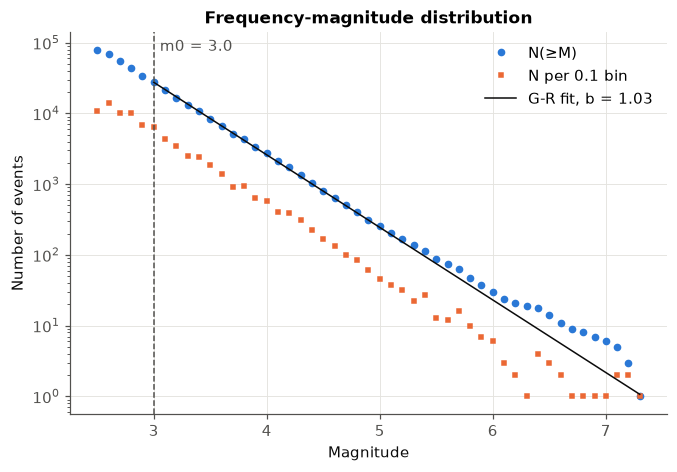

In [16]:
mags = eq["mag"].to_numpy()
fmd = eda.frequency_magnitude(mags)
mc = eda.mc_maxc(mags)
b, b_se = eda.b_value(mags, max(mc, M0))
print(f"Mc (max curvature + 0.2) = {mc:.1f}")
print(f"b-value above M{max(mc, M0):.1f} = {b:.3f} ± {b_se:.3f}")
fig, ax = plt.subplots(figsize=(7, 4.5))
plots.fmd_plot(fmd, max(mc, M0), b, ax=ax, label=f"m0 = {M0}");

Above the threshold the cumulative counts follow a straight line with b ≈ 1.0, the value
found in most tectonic regions: one unit of magnitude means about 10× fewer events. Below
about M2.8 (the maximum-curvature Mc) the curve flattens because the catalog misses small
events. Above about M5.5 the counts sit a little above the line. With only a few dozen
events there, that is a reminder that one b-value for a region mixing the San Andreas
system, the Eastern California Shear Zone and the Mendocino triple junction is an
approximation.

Completeness also varies in time. Just after a large mainshock, coda waves from the mainshock
and overlapping aftershocks hide small events (*short-term aftershock incompleteness*):

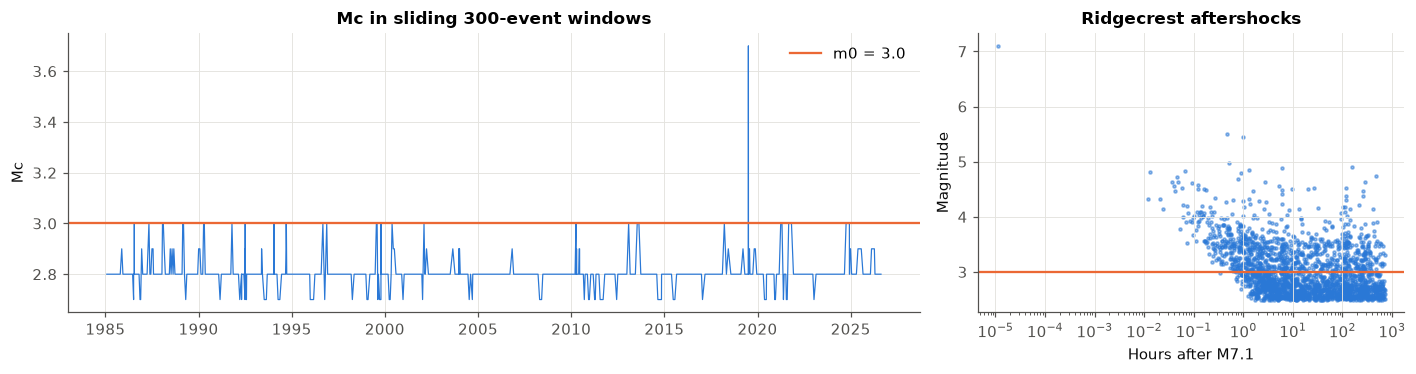

In [17]:
mc_t = eda.mc_over_time(eq, window=300, step=100)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(mc_t["time"], mc_t["mc"], color=plots.BLUE, lw=0.8)
axes[0].axhline(M0, color=plots.ORANGE, lw=1.5, label=f"m0 = {M0}")
axes[0].set(title="Mc in sliding 300-event windows", ylabel="Mc")
axes[0].legend()

t_rc = pd.Timestamp("2019-07-06 03:19:53", tz="UTC")  # Ridgecrest M7.1
near = eq[
    (eq["time"] > t_rc)
    & (eq["time"] < t_rc + pd.Timedelta(days=30))
    & (eda.haversine_km(35.77, -117.6, eq["lat"], eq["lon"]) < 100)
]
hrs = (near["time"] - t_rc) / pd.Timedelta(hours=1)
axes[1].scatter(hrs, near["mag"], s=4, color=plots.BLUE, alpha=0.5)
axes[1].set_xscale("log")
axes[1].axhline(M0, color=plots.ORANGE, lw=1.5)
axes[1].set(title="Ridgecrest aftershocks", xlabel="Hours after M7.1", ylabel="Magnitude")
plt.tight_layout()

Over the long run Mc stays around 2.8 and rarely exceeds 3.0. The clearest exception is
Ridgecrest in 2019. The right panel shows why: for the first hour after the M7.1 the
smallest recorded aftershocks are around M3.5 to M4, and the lower edge only reaches M2.5
after a few hours. A 300-event window smooths this out for most sequences, so the effect is
larger than the left panel suggests. Hence the threshold
**m0 = 3.0**, which is complete almost everywhere and matches the CSEP California
experiments. Even so, counts in the first hours after a big shock are undercounted. A model
needs to account for that, and scores in that period will be noisy.

## 7. Space and depth

Events above sea level: 4,756; deeper than 30 km: 476


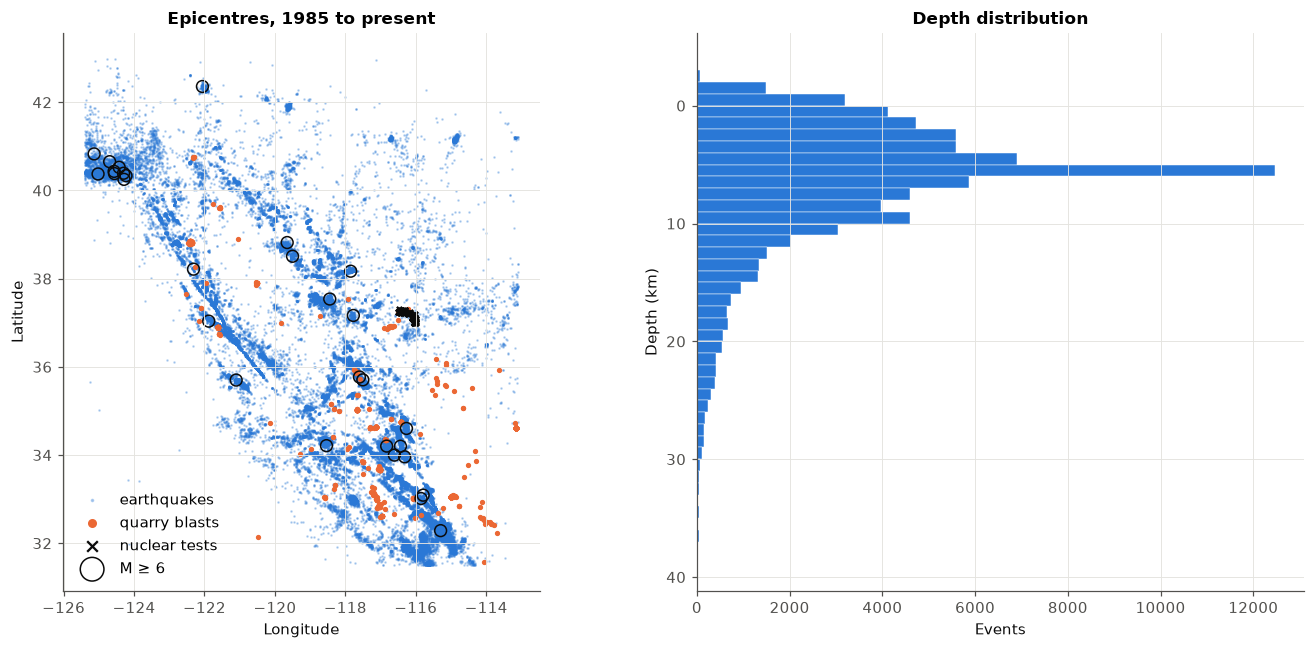

In [18]:
blasts = df[df["type"] == "quarry blast"]
nukes = df[df["type"].str.contains("nuclear", na=False)]
big = eq[eq["mag"] >= 6]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.scatter(eq["lon"], eq["lat"], s=0.5, color=plots.BLUE, alpha=0.3, label="earthquakes")
ax.scatter(blasts["lon"], blasts["lat"], s=6, color=plots.ORANGE, label="quarry blasts")
ax.scatter(nukes["lon"], nukes["lat"], s=12, marker="x", color=plots.INK, label="nuclear tests")
ax.scatter(big["lon"], big["lat"], s=60, facecolor="none", edgecolor=plots.INK, lw=1, label="M ≥ 6")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Epicentres, 1985 to present")
ax.set_aspect(1 / np.cos(np.radians(37)))
ax.legend(loc="lower left", markerscale=2)

ax = axes[1]
ax.hist(
    eq["depth_km"],
    bins=np.arange(-4, 40, 1),
    color=plots.BLUE,
    edgecolor="white",
    linewidth=0.3,
    orientation="horizontal",
)
ax.invert_yaxis()
ax.set(xlabel="Events", ylabel="Depth (km)", title="Depth distribution")
plt.tight_layout()
print(
    f"Events above sea level: {(eq['depth_km'] < 0).sum():,}; "
    f"deeper than 30 km: {(eq['depth_km'] > 30).sum():,}"
)

Seismicity outlines the plate boundary: the San Andreas system, the Eastern California
Shear Zone (Landers, Hector Mine, Ridgecrest), the Imperial Valley, and the Mendocino triple
junction offshore in the north. Blasts are concentrated in quarry districts and nuclear tests
at the Nevada Test Site, so including them would distort the spatial rate maps too.

Depth peaks at 5 to 10 km, the seismogenic upper crust. Spatial ETAS can treat depth as
secondary, but the deep offshore events in the north are a different tectonic setting.

## 8. The target as a time series: daily counts of M ≥ 3

count    15282.000
mean         1.620
std          7.601
min          0.000
25%          0.000
50%          1.000
75%          2.000
max        605.000
Name: count, dtype: float64

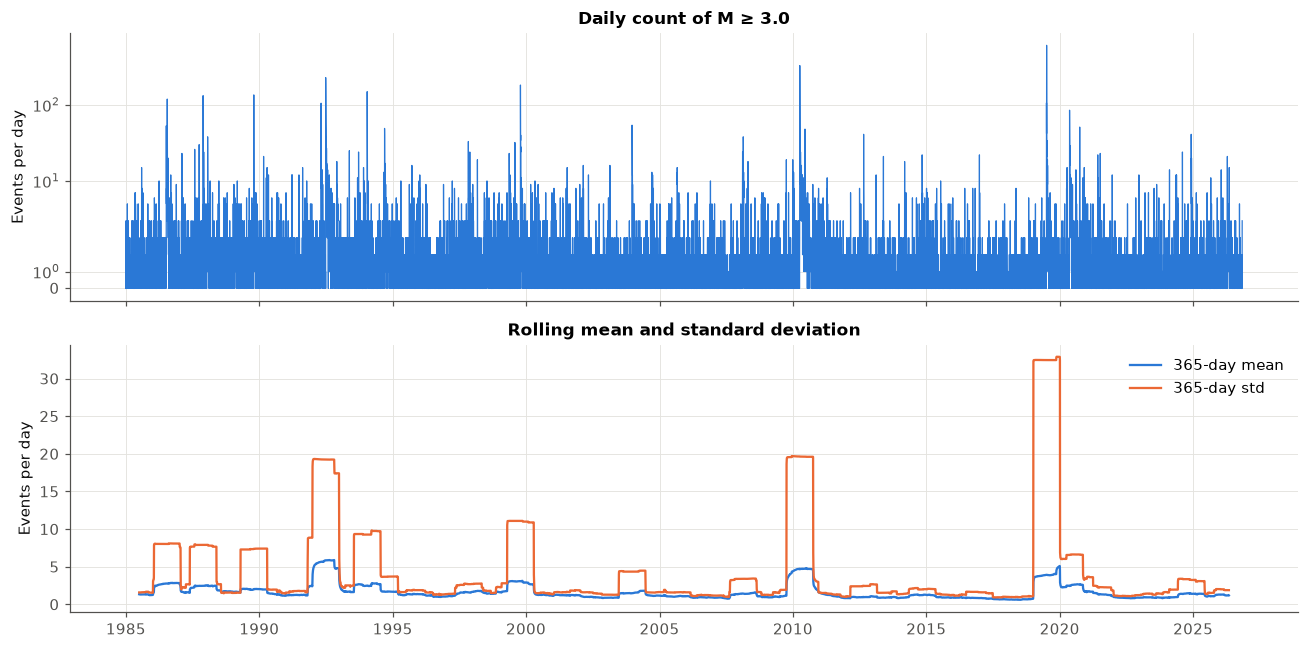

In [19]:
counts = eda.daily_counts(eq, M0)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plots.run_sequence_plot(counts, f"Daily count of M ≥ {M0}", "Events per day", ax=axes[0])
axes[0].set_yscale("symlog", linthresh=5)
roll = counts.rolling(365, center=True)
axes[1].plot(roll.mean(), color=plots.BLUE, label="365-day mean")
axes[1].plot(roll.std(), color=plots.ORANGE, label="365-day std")
axes[1].set(title="Rolling mean and standard deviation", ylabel="Events per day")
axes[1].legend()
plt.tight_layout()
counts.describe()

Course-style check: split the series into ten chunks and compare means and variances.

In [20]:
eda.chunk_stats(counts, 10).round(2)

,mean,variance,n
chunk,,,
1,2.04,32.03,1529
2,2.52,106.00,1529
3,1.64,25.72,1528
4,1.82,32.84,1528
5,1.17,6.53,1528
6,1.07,4.41,1528
7,1.88,96.65,1528
8,0.90,2.26,1528
9,2.08,264.54,1528


Zero days: 39%   skew: 44.7   max: 605 on 2019-07-06


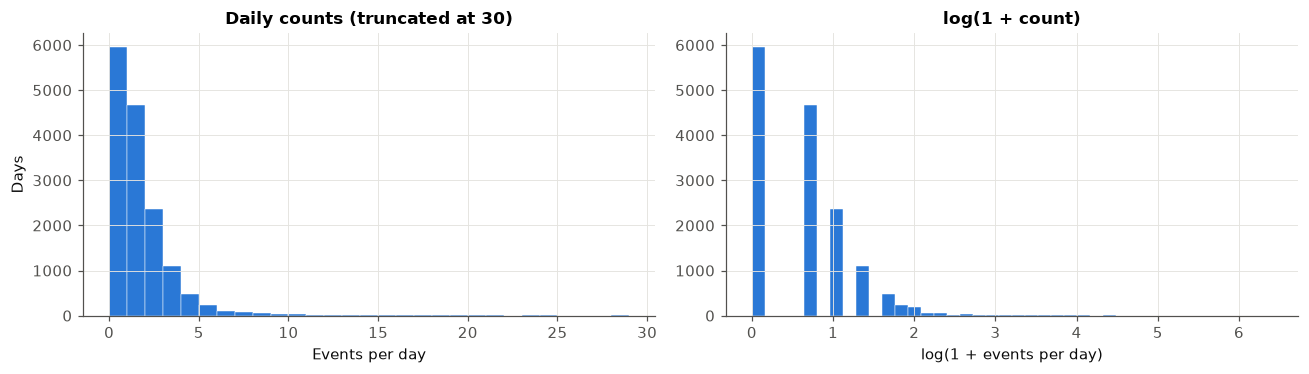

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(counts, bins=np.arange(0, 30), color=plots.BLUE, edgecolor="white", linewidth=0.3)
axes[0].set(title="Daily counts (truncated at 30)", xlabel="Events per day", ylabel="Days")
axes[1].hist(np.log1p(counts), bins=40, color=plots.BLUE, edgecolor="white", linewidth=0.3)
axes[1].set(title="log(1 + count)", xlabel="log(1 + events per day)")
plt.tight_layout()
print(
    f"Zero days: {(counts == 0).mean():.0%}   skew: {counts.skew():.1f}   "
    f"max: {counts.max()} on {counts.idxmax():%Y-%m-%d}"
)

In [22]:
adf = eda.adf_test(counts)
kp = eda.kpss_test(counts)
print(f"ADF:  stat = {adf['adf']:.2f}, p = {adf['p_value']:.3g}  (null: unit root)")
print(f"KPSS: stat = {kp['kpss']:.2f}, p = {kp['p_value']:.3g}  (null: stationary)")

ADF:  stat = -29.52, p = 0  (null: unit root)
KPSS: stat = 0.54, p = 0.0316  (null: stationary)


* About 40% of days have no M ≥ 3 event, and the busiest day has 605 (6 July 2019,
  Ridgecrest). The target is a **zero-inflated, very heavy-tailed count**. Even
  `log1p` leaves it skewed. Mean squared error on raw counts would be dominated by a few
  days; the CSEP Poisson or negative-binomial log-likelihood is the appropriate loss.
* ADF rejects a unit root, so there is no random-walk drift. KPSS is borderline: the
  chunk means and variances jump whenever a large sequence falls in a chunk. The series is
  **mean-reverting but not stationary in the usual sense**. Bursts relax back to a fairly
  steady background, which is exactly what ETAS describes. Differencing, the standard
  remedy in time-series courses, would destroy the aftershock signal.

## 9. Clustering and overdispersion

In [23]:
above = eq[eq["mag"] >= M0].reset_index(drop=True)
is_bg = eda.decluster_gk(above)
bg_counts = eda.daily_counts(above[is_bg], M0, counts.index[0], counts.index[-1])

rows = {}
for name, d, c in [("all M≥3", above, counts), ("declustered", above[is_bg], bg_counts)]:
    disp, ie = eda.dispersion_index(c), eda.interevent_stats(d["time"])
    rows[name] = {
        "events": len(d),
        "mean/day": disp["mean"],
        "variance/day": disp["variance"],
        "dispersion (var/mean)": disp["dispersion"],
        "inter-event CV": ie["cv"],
    }
print(f"Background (mainshock) fraction: {is_bg.mean():.0%}")
pd.DataFrame(rows).T.round(3)

Background (mainshock) fraction: 27%


,events,mean/day,variance/day,dispersion (var/mean),inter-event CV
all M≥3,24762.0,1.620,57.782,35.660,1.626
declustered,6679.0,0.437,0.446,1.019,0.996


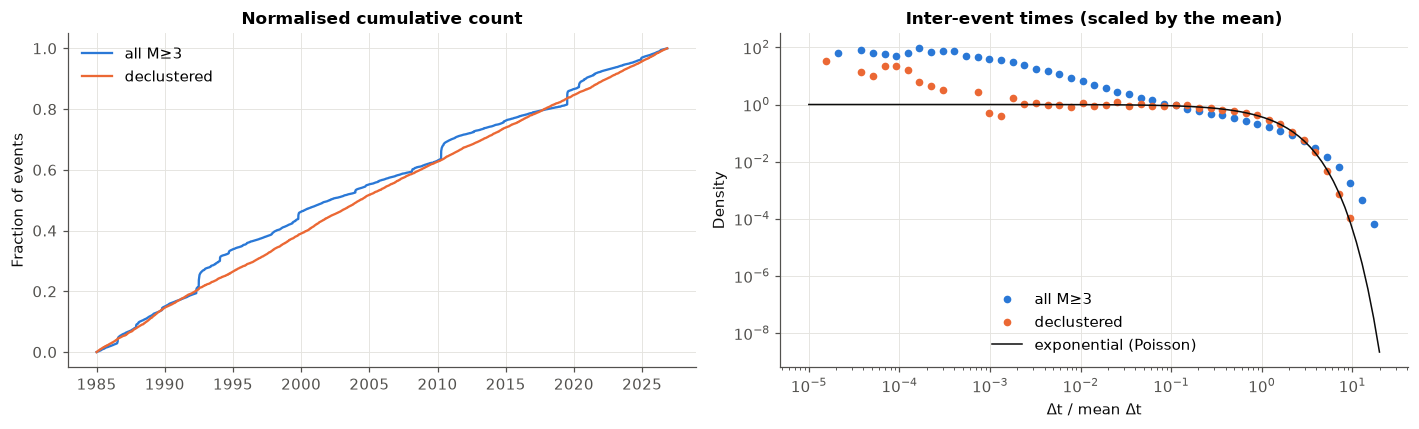

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, d, color in [("all M≥3", above, plots.BLUE), ("declustered", above[is_bg], plots.ORANGE)]:
    axes[0].plot(d["time"], np.arange(1, len(d) + 1) / len(d), color=color, label=name)
    dt = np.diff(d["time"].to_numpy()).astype("timedelta64[s]").astype(float) / 86400
    dt = dt[dt > 0] / dt[dt > 0].mean()
    bins = np.logspace(-5, 1.3, 50)
    dens, edges = np.histogram(dt, bins=bins, density=True)
    axes[1].loglog(np.sqrt(edges[1:] * edges[:-1]), dens, "o", ms=4, color=color, label=name)
xs = np.logspace(-5, 1.3, 100)
axes[1].loglog(xs, np.exp(-xs), color=plots.INK, lw=1, label="exponential (Poisson)")
axes[0].set(title="Normalised cumulative count", ylabel="Fraction of events")
axes[1].set(title="Inter-event times (scaled by the mean)", xlabel="Δt / mean Δt", ylabel="Density")
for ax in axes:
    ax.legend()
plt.tight_layout()

This is the key result of the EDA:

* **All events:** the daily variance is about 35× the mean. A Poisson process would give 1.
  Inter-event times have CV ≈ 1.6, far more short gaps than an exponential, and the
  cumulative curve rises in steps.
* **After declustering** (Gardner-Knopoff windows): about 27% of M ≥ 3 events are
  mainshocks. Their dispersion is ≈ 1.0, CV ≈ 1.0, inter-event times follow the exponential,
  and the cumulative curve is straight. **The background is Poisson.** The exception is a
small excess of very short gaps: event pairs that window declustering misses.

So the series is a near-constant Poisson background plus triggered cascades (about 70% of
events), which is the ETAS decomposition. A useful ML model has to beat ETAS at predicting
the triggered part, since the background has essentially no time structure to learn.

## 10. Heteroskedasticity

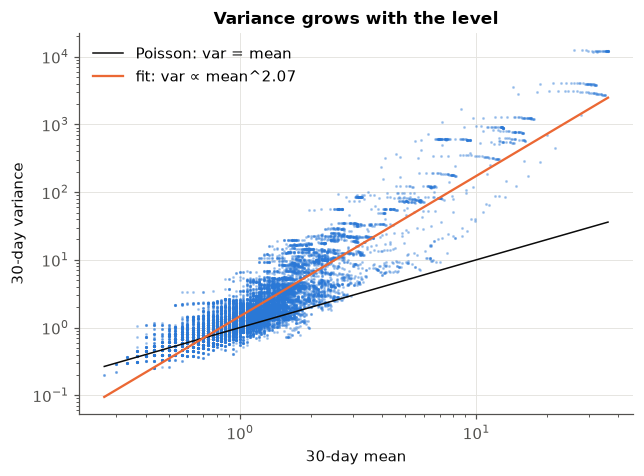

In [25]:
r = counts.rolling(30)
mv = pd.DataFrame({"mean": r.mean(), "var": r.var()}).dropna()
mv = mv[(mv["mean"] > 0) & (mv["var"] > 0)]
slope, intercept = np.polyfit(np.log10(mv["mean"]), np.log10(mv["var"]), 1)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(mv["mean"], mv["var"], ".", ms=2, alpha=0.3, color=plots.BLUE)
xs = np.logspace(np.log10(mv["mean"].min()), np.log10(mv["mean"].max()), 50)
ax.loglog(xs, xs, color=plots.INK, lw=1, label="Poisson: var = mean")
ax.loglog(
    xs, 10**intercept * xs**slope, color=plots.ORANGE, lw=1.5, label=f"fit: var ∝ mean^{slope:.2f}"
)
ax.set(xlabel="30-day mean", ylabel="30-day variance", title="Variance grows with the level")
ax.legend();

In [26]:
feats = eda.daily_features(eq, M0)
x_cols = ["count", "count_7d", "max_mag", "log_days_since_m5"]
het = eda.heteroskedasticity_tests(feats, "y_next", x_cols)
arch = eda.arch_test(counts)
feats_log = feats.assign(
    y_next=np.log1p(feats["y_next"]),
    count=np.log1p(feats["count"]),
    count_7d=np.log1p(feats["count_7d"]),
)
het_log = eda.heteroskedasticity_tests(feats_log, "y_next", x_cols)
pd.DataFrame(
    {
        "raw counts": [het["breusch_pagan_p"], het["white_p"], het["r2"]],
        "log1p counts": [het_log["breusch_pagan_p"], het_log["white_p"], het_log["r2"]],
    },
    index=["Breusch-Pagan p", "White p", "OLS R²"],
).style.format("{:.3g}")

,raw counts,log1p counts
Breusch-Pagan p,7.18e-36,2.57e-61
White p,5.13e-60,3.32e-168
OLS R²,0.158,0.149


In [27]:
print(f"ARCH LM test on daily counts (7 lags): LM = {arch['lm']:.1f}, p = {arch['p_value']:.2g}")

ARCH LM test on daily counts (7 lags): LM = 51.4, p = 7.7e-09


Heteroskedasticity is present on every check:

* Variance grows faster than the mean (slope > 1 on log-log). For a Poisson count the
  slope would be 1. That is the signature of a negative binomial, or more precisely a
  self-exciting process.
* Breusch-Pagan and White reject constant residual variance for a linear model of
  tomorrow's count, both raw and after `log1p`. R² stays around 0.15 either way, and the
  transform doesn't make the noise homoskedastic.
* The ARCH test finds volatility clustering: busy days follow busy days.

So ordinary least squares and MSE-trained networks are mis-specified for this target. Use a
count likelihood whose variance depends on the predicted rate: Poisson with a
history-dependent rate (as ETAS does) or negative binomial. That is also what CSEP scores.

## 11. Seasonality: hour, weekday, month

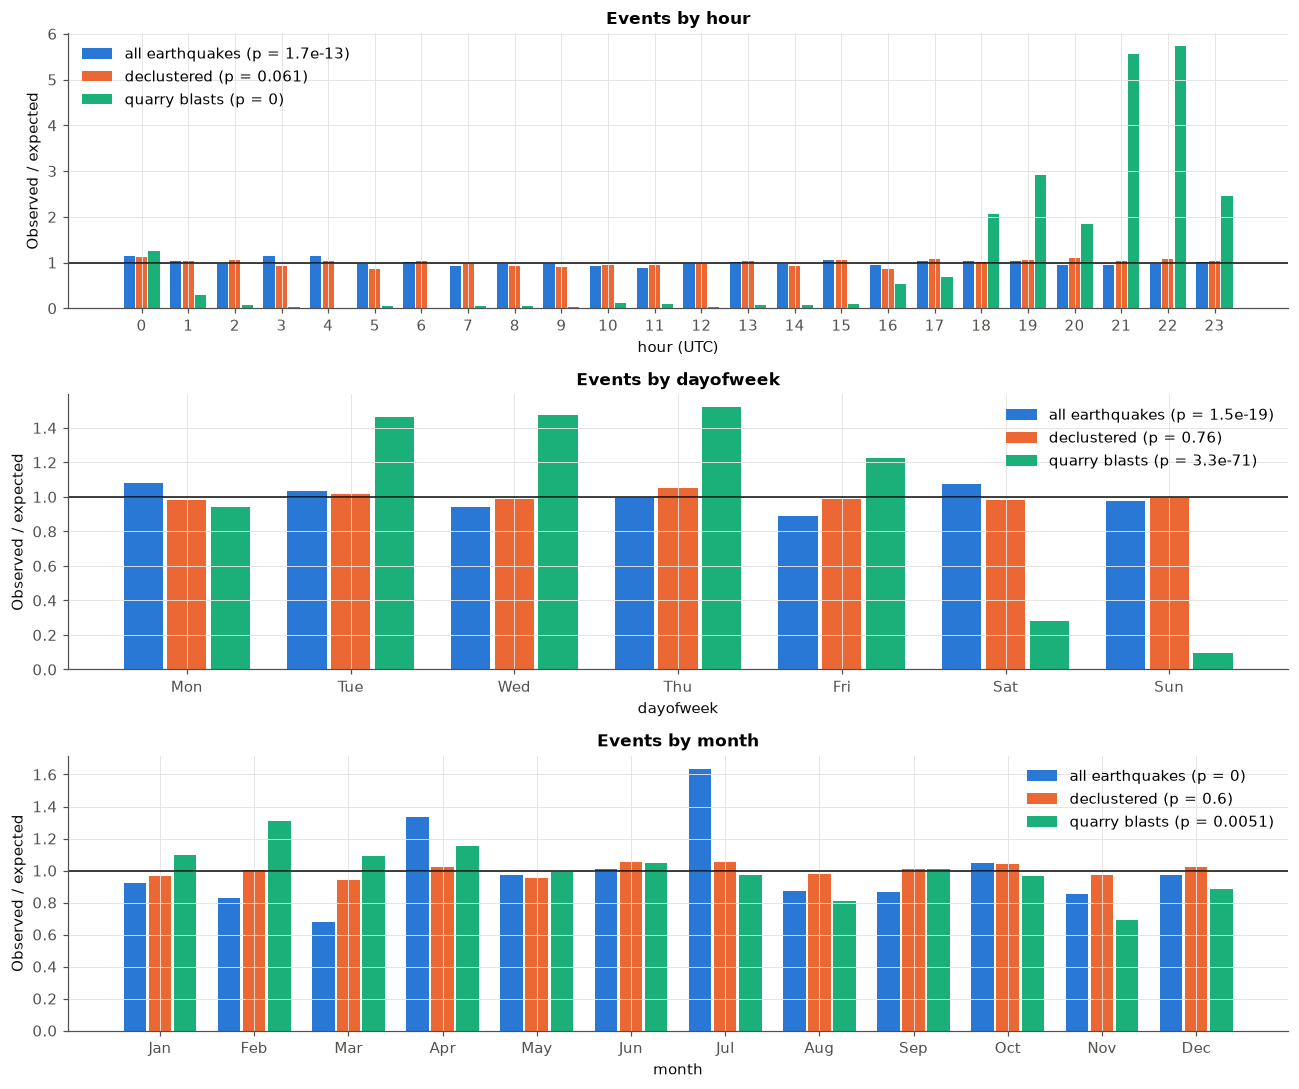

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, by in zip(axes, ["hour", "dayofweek", "month"], strict=True):
    profs = {
        "all earthquakes": eda.seasonal_profile(above["time"], by),
        "declustered": eda.seasonal_profile(above.loc[is_bg, "time"], by),
        "quarry blasts": eda.seasonal_profile(blasts["time"], by),
    }
    plots.seasonal_bars(profs, by, ax=ax)
axes[0].set_xlabel("hour (UTC)")
plt.tight_layout()

Read each panel with the chi-square p-values in the legend in mind:

* **Quarry blasts** show strong human cycles: 18:00 to 24:00 UTC (late morning to
  afternoon Pacific time) and almost never at weekends. If they stayed in the catalog
  they would create a fake daily cycle, one more reason to remove them.
* **All earthquakes** appear to show significant hourly, weekday and monthly
  "seasonality". The monthly spikes are July (Ridgecrest 2019, plus the Landers
  aftershocks after its 28 June 1992 mainshock) and April (Petrolia 1992, El Mayor-Cucapah
  2010). This is an artefact of
  clustering: one large sequence fills one calendar bin, and the chi-square test assumes
  independent events, which aftershocks are not.
* **Declustered earthquakes** show no significant weekday or monthly pattern (p ≈ 0.6 to
  0.8). The hourly test is borderline (p ≈ 0.06), with all hourly ratios within about 15% of
  1, so it isn't significant at the 5% level.

A seasonal decomposition of monthly counts tells the same story:

Seasonal share of non-trend variance, all events: 1.1%
Seasonal share, declustered: 25.9%
Same STL on Poisson noise with the declustered rate (50 runs): 29.1% on average, 90% range 24.7% to 33.1%


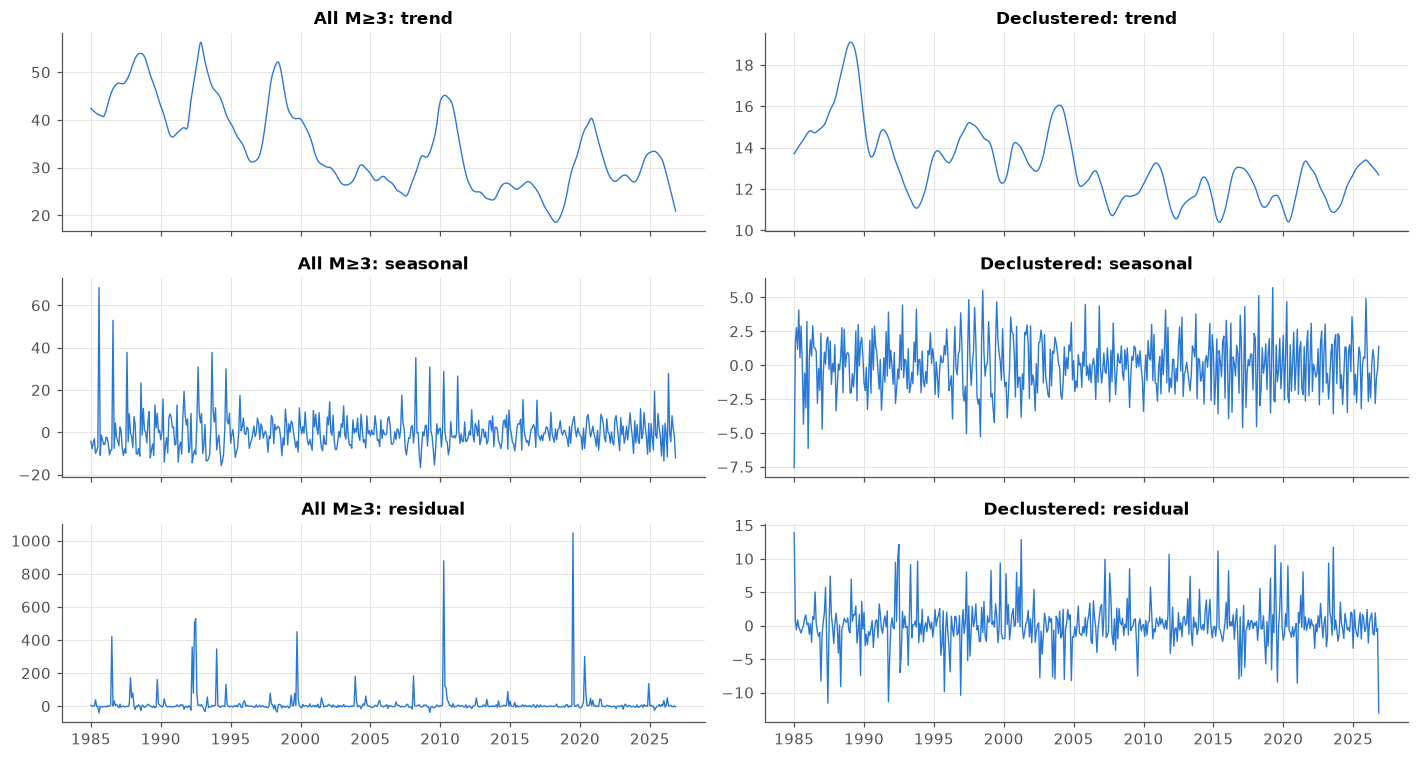

In [29]:
stl_all = eda.stl_monthly(counts)
stl_bg = eda.stl_monthly(bg_counts)
fig, axes = plt.subplots(3, 2, figsize=(13, 7), sharex=True)
for j, (name, res) in enumerate([("All M≥3", stl_all), ("Declustered", stl_bg)]):
    for i, (part, s) in enumerate(
        [("trend", res.trend), ("seasonal", res.seasonal), ("residual", res.resid)]
    ):
        axes[i, j].plot(s.index, s.to_numpy(), lw=0.9, color=plots.BLUE)
        axes[i, j].set_title(f"{name}: {part}")
plt.tight_layout()
null = eda.seasonal_share_null(bg_counts, n_sims=50)
print(f"Seasonal share of non-trend variance, all events: {eda.seasonal_share(stl_all):.1%}")
print(f"Seasonal share, declustered: {eda.seasonal_share(stl_bg):.1%}")
print(
    f"Same STL on Poisson noise with the declustered rate (50 runs): "
    f"{null.mean():.1%} on average, 90% range {np.percentile(null, 5):.1%} to "
    f"{np.percentile(null, 95):.1%}"
)

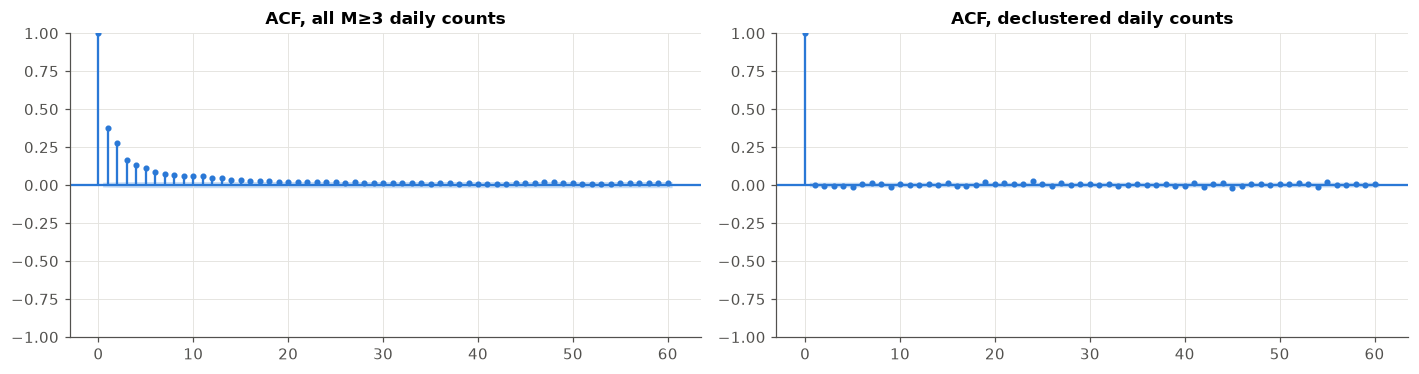

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(counts, lags=60, ax=axes[0], title="ACF, all M≥3 daily counts", markersize=3)
plot_acf(bg_counts, lags=60, ax=axes[1], title="ACF, declustered daily counts", markersize=3)
plt.tight_layout()

For all events the seasonal component is tiny next to the residual, which is dominated by
aftershock bursts. For the declustered series STL attributes a larger share to
"seasonality", but no more than it finds in pure Poisson noise of the same rate. STL always
extracts some pattern, so the share only means something next to that baseline. The
declustered ACF lies within the confidence band at all lags. The ACF of all
events decays slowly over weeks, which is Omori decay. **There is no seasonality to model.**
Calendar features (day of week, month) should be left out. Proposed links between tides or
seasonal loading and earthquakes are real research topics, but they are far too weak to show
up in an M ≥ 3 regional count.

## 12. Aftershock decay: the Omori-Utsu law

,n,K,c,p
Landers M7.3 (1992),1095.0,266.577,0.519,1.207
Hector Mine M7.1 (1999),538.0,94.247,0.173,1.178
Ridgecrest M7.1 (2019),1043.0,112.854,0.020,1.159


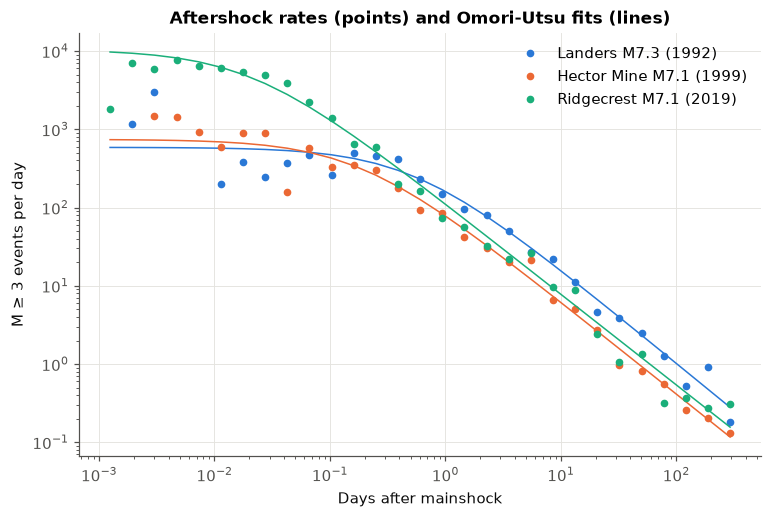

In [31]:
sequences = {
    "Landers M7.3 (1992)": (pd.Timestamp("1992-06-28 11:57:34", tz="UTC"), 34.2, -116.44),
    "Hector Mine M7.1 (1999)": (pd.Timestamp("1999-10-16 09:46:44", tz="UTC"), 34.6, -116.27),
    "Ridgecrest M7.1 (2019)": (pd.Timestamp("2019-07-06 03:19:53", tz="UTC"), 35.77, -117.6),
}
T_END = 365.0
fig, ax = plt.subplots(figsize=(8, 5))
fits = {}
for (name, (t0, la, lo)), color in zip(sequences.items(), plots.SERIES, strict=True):
    sel = above[
        (above["time"] > t0)
        & (above["time"] <= t0 + pd.Timedelta(days=T_END))
        & (eda.haversine_km(la, lo, above["lat"], above["lon"]) < 75)
    ]
    dt = ((sel["time"] - t0) / pd.Timedelta(days=1)).to_numpy()
    fit = eda.fit_omori(dt, T_END)
    fits[name] = fit
    bins = np.logspace(-3, np.log10(T_END), 30)
    n, edges = np.histogram(dt, bins=bins)
    mid = np.sqrt(edges[1:] * edges[:-1])
    ax.loglog(mid, n / np.diff(edges), "o", ms=4, color=color, label=name)
    ax.loglog(mid, eda.omori_rate(mid, fit["K"], fit["c"], fit["p"]), color=color, lw=1)
ax.set(
    xlabel="Days after mainshock",
    ylabel="M ≥ 3 events per day",
    title="Aftershock rates (points) and Omori-Utsu fits (lines)",
)
ax.legend()
pd.DataFrame(fits).T[["n", "K", "c", "p"]].astype(float).round(3)

All three sequences decay as a power law from hours to a year, with **p ≈ 1.15 to 1.2**,
inside the typical range of about 1.0 to 1.3. The flat start (the `c` value) shrinks from
about half a day for Landers in 1992 to about half an hour for Ridgecrest in 2019. That is
mostly better detection of early aftershocks by the modern network, the incompleteness from
section 6, rather than a physical difference. This law is the temporal kernel inside ETAS. The aftershock
productivity of each sequence (K) varies, and that variation is something an ML model could
learn from inputs such as the mainshock's location and fault setting.

## 13. Features and the target

In [32]:
feats.drop(columns=["day_of_week", "month"]).describe().T[["mean", "50%", "std", "max"]]

,mean,50%,std,max
count,1.620,1.000,7.602,605.000
max_mag,3.302,3.120,0.513,7.300
mean_depth_km,7.741,6.591,5.502,71.063
log_moment,8.858,13.825,7.115,20.072
count_3d,4.860,3.000,17.104,753.000
count_7d,11.341,7.000,31.385,901.000
count_30d,48.590,33.000,82.211,1084.000
count_365d,586.759,457.000,377.860,2148.000
max_mag_7d,4.059,3.980,0.610,7.300
max_mag_30d,4.715,4.590,0.635,7.300


In [33]:
corr = eda.feature_target_correlation(feats)
corr.style.format(
    {"pearson_r": "{:.3f}", "spearman_rho": "{:.3f}", "pearson_p": "{:.2g}", "spearman_p": "{:.2g}"}
)

,pearson_r,pearson_p,spearman_rho,spearman_p,n
feature,,,,,
count_30d,0.180,4.5e-111,0.251,8.9e-218,15281
count_7d,0.297,4.6e-309,0.227,5.2e-178,15281
count_365d,0.067,1.5e-16,0.210,3.5e-152,15281
count_3d,0.364,0,0.210,1.4e-151,15281
count,0.376,0,0.178,3.4e-109,15281
log_days_since_m5,-0.141,1.2e-68,-0.161,9.3e-89,15258
days_since_m5,-0.070,4.7e-18,-0.161,9.3e-89,15258
log_moment,0.067,1.6e-16,0.159,6.4e-87,15281
max_mag_7d,0.179,1.1e-110,0.151,6.9e-79,15281


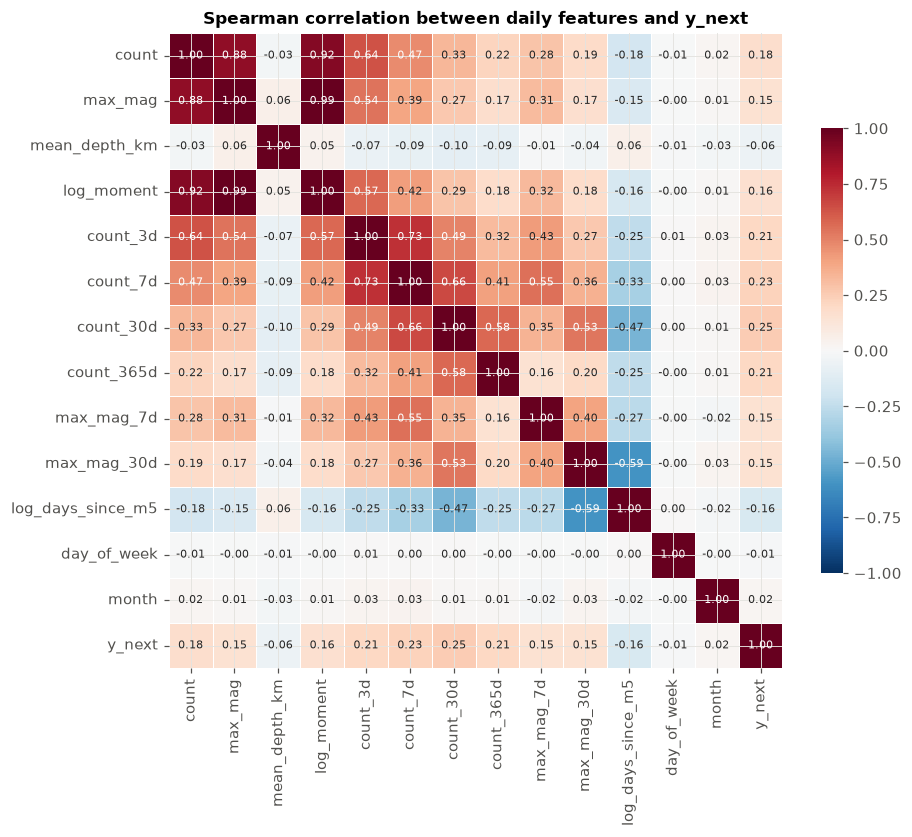

In [34]:
mat = feats.drop(columns=["days_since_m5"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    mat,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.7},
    ax=ax,
)
ax.set_title("Spearman correlation between daily features and y_next");

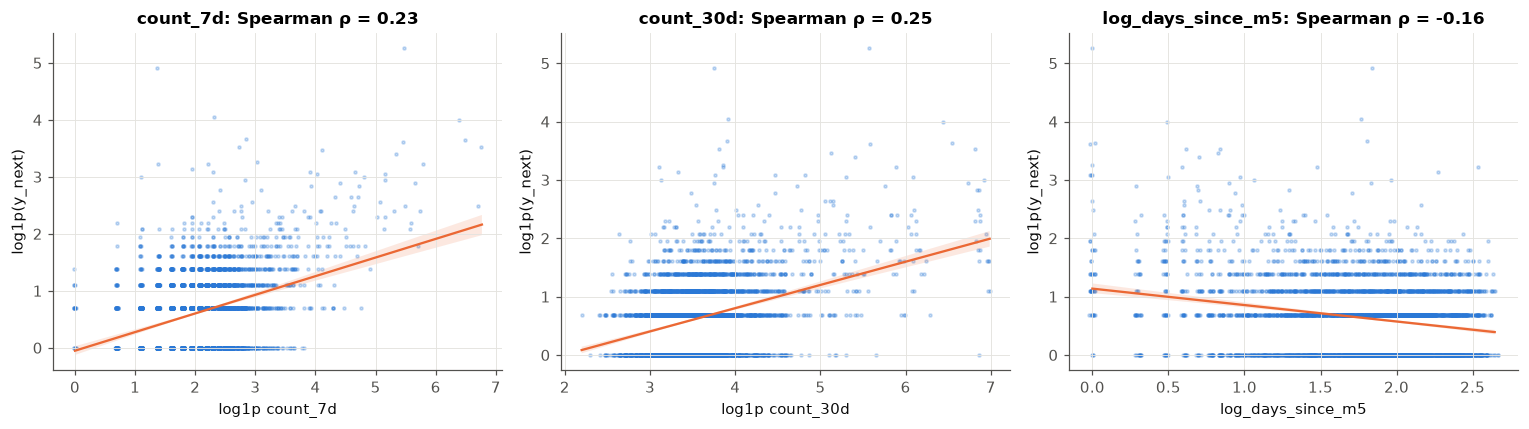

In [35]:
top = ["count_7d", "count_30d", "log_days_since_m5"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sample = feats.dropna(subset=top).sample(4000, random_state=0)
for ax, col in zip(axes, top, strict=True):
    logged = col.startswith("count")
    x = np.log1p(sample[col]) if logged else sample[col]
    sns.regplot(
        x=x,
        y=np.log1p(sample["y_next"]),
        ax=ax,
        scatter_kws={"s": 4, "alpha": 0.25, "color": plots.BLUE},
        line_kws={"color": plots.ORANGE, "lw": 1.5},
        x_jitter=0.02,
    )
    rho = corr.loc[col, "spearman_rho"]
    ax.set(
        xlabel=("log1p " if logged else "") + col,
        ylabel="log1p(y_next)",
        title=f"{col}: Spearman ρ = {rho:.2f}",
    )
plt.tight_layout()

In [36]:
for col in ["day_of_week", "month"]:
    groups = [g["y_next"].to_numpy() for _, g in feats.groupby(col)]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis y_next by {col}: H = {h:.1f}, p = {p:.3g}")

Kruskal-Wallis y_next by day_of_week: H = 6.5, p = 0.365
Kruskal-Wallis y_next by month: H = 30.0, p = 0.00157


* **Recent activity is the strongest predictor.** Rolling counts (`count_30d`, `count_7d`,
  `count_3d`), released moment and recent maximum magnitude correlate with tomorrow's count
  at Spearman ρ ≈ 0.15 to 0.25, and time since the last M ≥ 5 correlates negatively. These
  are the ETAS ingredients: more recent and larger events give a higher rate, which decays
  with time since a big shock.
* Pearson is highest for same-day `count`, but Spearman ranks the longer windows above it:
  Pearson is dominated by a few huge sequence days, while Spearman reflects typical days.
* **Calendar features have little or no information** (|ρ| ≤ 0.02). The Kruskal-Wallis
  test finds no weekday effect. The month effect is significant only because a few large
  sequences fall in particular months, as section 11 showed.
* The features are strongly correlated with each other (same-day `count`, `max_mag` and
  `log_moment` have ρ ≈ 0.9 to 0.99), so a linear model needs regularisation, and feature importances will be unstable.
* Even the best feature has |ρ| ≈ 0.25. Day-to-day counts are largely unpredictable from
  catalog features, which is why ETAS is hard to beat.

## 14. Summary and what it means for the model

| Check | Finding | Consequence |
| --- | --- | --- |
| Columns | 22 columns: event, quality and bookkeeping | Model on time, location and magnitude; quality columns only as flags |
| Missing values | Only in quality columns, mostly the older catalog | No imputation; quality features would encode the era |
| Non-earthquakes | about 1.6% blasts, explosions and nuclear tests | Remove them; they create fake daily and weekly cycles |
| Magnitude | Gutenberg-Richter, b ≈ 1.0, Mc ≈ 2.8 | Use m0 = 3.0; magnitude outliers are the signal |
| Completeness | Drops for hours after large mainshocks | Expect undercounting and noisy scores right after big events |
| Target | Zero-inflated, heavy-tailed, mean-reverting | Score with Poisson/NB likelihood, not MSE; no differencing |
| Clustering | Dispersion about 35 overall, about 1.0 declustered | Poisson background plus about 70% triggered events: the ETAS structure |
| Heteroskedasticity | Variance grows with the rate; BP, White and ARCH all reject | Use a count likelihood with rate-dependent variance |
| Seasonality | None after declustering | No calendar features |
| Aftershock decay | Omori-Utsu, p ≈ 1.15 to 1.2 | The kernel to keep; productivity per sequence is learnable |
| Features | Recent-activity features best, Spearman ρ ≈ 0.25 | Little room to improve on ETAS: the bar is real |

**Next:** move to spatial ETAS on the CSEP RELM grid. Then give the ML model the residual
structure ETAS leaves behind, such as sequence-specific productivity and spatial
anisotropy, rather than features this EDA shows carry no information.